# Testing and Improving the Content-Based Recommender

## Objectives

1. Load the existing content-based recommendation engine.
2. Test recommendations for multiple movies.
3. Check how the system handles incorrect and incomplete movie titles.
4. Verify that similarity scores are valid.
5. Test recommendation quality and consistency.
6. Understand the efficiency of on-demand similarity calculation.

Today, we will focus on making our recommendation engine more reliable and efficient.

## Import libraries and load the recommender

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

from src.content_based_recommender import ContentBasedRecommender

recommender = ContentBasedRecommender()

print("Content-Based Recommender Loaded Successfully!")
print("Total movies:", len(recommender.movies))

Content-Based Recommender Loaded Successfully!
Total movies: 9742


## 1. Testing Recommendations for Multiple Movies

A recommendation system should work for different movies, not just one selected movie.

We will test the system using several movie titles and observe the recommendations.

## Test multiple movies

In [2]:
test_movies = [
    "Toy Story (1995)",
    "Jumanji (1995)",
    "The Matrix (1999)",
    "Jurassic Park (1993)"
]

for movie in test_movies:

    print(f"\nRecommendations for: {movie}")
    print("=" * 70)

    try:
        results = recommender.recommend(movie, top_n=5)
        display(results)

    except ValueError as error:
        print("Error:", error)


Recommendations for: Toy Story (1995)


,movieId,title,genres,similarity_score
0,103755,Turbo (2013),Adventure|Animation|Children|Comedy|Fantasy,1.0
1,4016,"Emperor's New Groove, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,1.0
2,3754,"Adventures of Rocky and Bullwinkle, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,1.0
3,3114,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,1.0
4,91355,Asterix and the Vikings (Astérix et les Viking...,Adventure|Animation|Children|Comedy|Fantasy,1.0



Recommendations for: Jumanji (1995)


,movieId,title,genres,similarity_score
0,126,"NeverEnding Story III, The (1994)",Adventure|Children|Fantasy,1.0
1,60,"Indian in the Cupboard, The (1995)",Adventure|Children|Fantasy,1.0
2,119655,Seventh Son (2014),Adventure|Children|Fantasy,1.0
3,1009,Escape to Witch Mountain (1975),Adventure|Children|Fantasy,1.0
4,126142,The Cave of the Golden Rose (1991),Adventure|Children|Fantasy,1.0



Recommendations for: The Matrix (1999)


{'message': 'No matching movie title was found.', 'matches': []}


Recommendations for: Jurassic Park (1993)


,movieId,title,genres,similarity_score
0,1356,Star Trek: First Contact (1996),Action|Adventure|Sci-Fi|Thriller,1.0
1,1374,Star Trek II: The Wrath of Khan (1982),Action|Adventure|Sci-Fi|Thriller,1.0
2,3703,"Road Warrior, The (Mad Max 2) (1981)",Action|Adventure|Sci-Fi|Thriller,1.0
3,3638,Moonraker (1979),Action|Adventure|Sci-Fi|Thriller,1.0
4,1591,Spawn (1997),Action|Adventure|Sci-Fi|Thriller,1.0


## 2. Testing Invalid and Incomplete Movie Titles

Users may enter an incorrect or incomplete movie title.

A reliable recommendation system should handle these situations gracefully instead of crashing.

We will test:
- An exact movie title.
- A partially entered movie title.
- A movie title that does not exist in the dataset.

## Test different inputs

In [3]:
test_inputs = [
    "Toy Story (1995)",
    "Toy Story",
    "This Movie Does Not Exist"
]

for movie in test_inputs:

    print(f"\nUser Input: {movie}")
    print("-" * 60)

    try:
        results = recommender.recommend(movie, top_n=5)
        display(results)

    except ValueError as error:
        print("Message:", error)


User Input: Toy Story (1995)
------------------------------------------------------------


,movieId,title,genres,similarity_score
0,103755,Turbo (2013),Adventure|Animation|Children|Comedy|Fantasy,1.0
1,4016,"Emperor's New Groove, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,1.0
2,3754,"Adventures of Rocky and Bullwinkle, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,1.0
3,3114,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,1.0
4,91355,Asterix and the Vikings (Astérix et les Viking...,Adventure|Animation|Children|Comedy|Fantasy,1.0



User Input: Toy Story
------------------------------------------------------------


{'message': 'Exact title not found. Possible matches:',
 'matches': ['Toy Story (1995)', 'Toy Story 2 (1999)', 'Toy Story 3 (2010)']}


User Input: This Movie Does Not Exist
------------------------------------------------------------


{'message': 'No matching movie title was found.', 'matches': []}

## 3. Checking Recommendation Validity

We need to verify that our recommendation engine produces valid results.

We will check:

1. Recommendations are not empty.
2. The selected movie is not recommended to itself.
3. Similarity scores are between 0 and 1.
4. The requested number of recommendations is returned when enough movies are available.

These checks help identify errors in our recommendation algorithm.

## Validate recommendations

In [4]:
movie_title = "Toy Story (1995)"

results = recommender.recommend(movie_title, top_n=10)

# Check 1: Recommendations should not be empty
assert len(results) > 0, "No recommendations returned!"

# Check 2: Selected movie should not appear in recommendations
assert movie_title not in results["title"].values, \
    "The selected movie was recommended to itself!"

# Check 3: Similarity scores should be between 0 and 1
assert results["similarity_score"].between(0, 1).all(), \
    "Invalid similarity scores found!"

# Check 4: Requested number of recommendations
assert len(results) == min(10, len(recommender.movies) - 1), \
    "Unexpected number of recommendations!"

print("All recommendation validity checks passed!")

All recommendation validity checks passed!


## 4. Testing Recommendation Consistency

A recommendation system should produce consistent results for the same input when the dataset and model remain unchanged.

We will request recommendations twice for the same movie and compare the results.

## Compare repeated recommendations

In [5]:
first_result = recommender.recommend(
    "Toy Story (1995)",
    top_n=10
)

second_result = recommender.recommend(
    "Toy Story (1995)",
    top_n=10
)

pd.testing.assert_frame_equal(
    first_result.reset_index(drop=True),
    second_result.reset_index(drop=True)
)

print("Consistency test passed!")
print("The recommender produces the same results for the same input.")

Consistency test passed!
The recommender produces the same results for the same input.


## 5. Visualizing Similarity Scores

Numerical results are useful, but visualizations make it easier to understand recommendation scores.

We will create a horizontal bar chart showing the similarity scores of the top 10 movies recommended for Toy Story (1995).

## Plot similarity scores

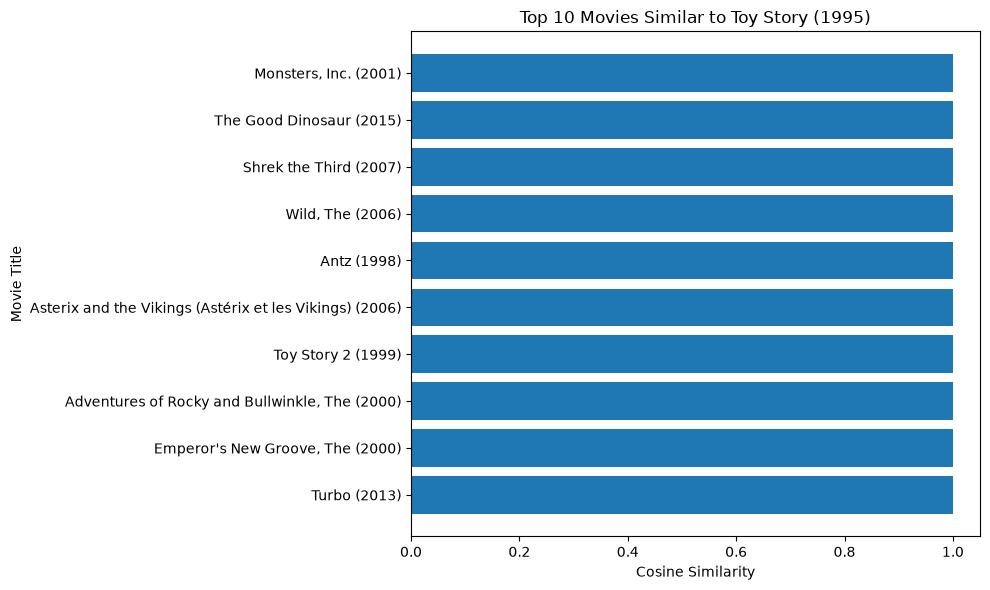

In [6]:
recommendations = recommender.recommend(
    "Toy Story (1995)",
    top_n=10
)

plot_data = recommendations.sort_values(
    "similarity_score",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data["title"],
    plot_data["similarity_score"]
)

plt.xlabel("Cosine Similarity")
plt.ylabel("Movie Title")
plt.title("Top 10 Movies Similar to Toy Story (1995)")

plt.tight_layout()
plt.show()

## 6. Understanding Recommendation Efficiency

In our initial implementation, the system calculated and stored a complete movie-to-movie similarity matrix.

However, we only need similarity scores for the movie selected by the user.

Calculating similarities on demand can reduce memory usage because we do not need to store the entire similarity matrix.

Our improved implementation calculates similarity only when a recommendation request is made.

## Check the improved implementation

In [7]:
if hasattr(recommender, "similarity_matrix"):
    print("The old full similarity matrix is still being stored.")
    print("Review your Day 5 implementation.")

else:
    print("On-demand similarity calculation is being used.")
    print("The full similarity matrix is not stored.")

print("\nMovie feature matrix shape:")
print(recommender.movie_vectors.shape)

On-demand similarity calculation is being used.
The full similarity matrix is not stored.

Movie feature matrix shape:
(9742, 21)


# Conclusion

Today, we tested and improved our content-based recommendation system.

### Work Completed

- Loaded the existing content-based recommendation engine.
- Tested recommendations for multiple movies.
- Tested exact, incomplete, and invalid movie titles.
- Checked recommendation validity.
- Verified that the selected movie is not recommended to itself.
- Checked similarity score ranges.
- Tested recommendation consistency.
- Visualized movie similarity scores.
- Improved memory efficiency using on-demand similarity calculation.

### Limitations

- The model mainly uses movie genres.
- It does not understand the actual story or meaning of a movie.
- It does not learn individual user preferences.
- Movies with similar genres may not necessarily appeal to the same audience.

### Next Step

Develop a Collaborative Filtering Recommendation System using user ratings.

This will allow us to learn from user preferences and compare a second recommendation approach with our content-based model.